# Model Training & Evaluation -- CNNsa-BiLSTM
Notebook ini adalah controller untuk melatih dan mengevaluasi model **CNNsa-BiLSTM** pada dataset BISINDO.

## 1. Setup & Cek Dataset

In [3]:
import sys
import torch
from pathlib import Path

# Append root path (notebook di Training/CNNsaBiLSTM/ -> naik 2 level ke ROOT)
sys.path.insert(0, str(Path.cwd().parent.parent))

from Training.CNNsaBiLSTM.Config.train_config import verify_data_exists, create_output_dirs
from Training.Scripts.device_utils import get_device

# Pastikan data .npz hasil FeatureExtraction sudah ada
verify_data_exists()
create_output_dirs()

# get_device() print detail GPU (atau warning jelas kalau jatuh ke CPU)
device = get_device()


[TrainConfig] Semua file sequence ditemukan.
[TrainConfig] ROOT          : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android
[TrainConfig] Sequence Dir  : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Datasets\WLBisindo_Features\sequences
[TrainConfig] Checkpoint Dir: D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Training\Output\cnnsa_bilstm\checkpoints
[TrainConfig] Log Dir       : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Training\Output\cnnsa_bilstm\logs
[Device] GPU terdeteksi : NVIDIA GeForce RTX 5060 (compute capability sm_120)
[Device] CUDA runtime   : 12.8 (build PyTorch)


## 2. Model Summary (Proposed CNNsa-BiLSTM)
Mari kita lihat detail arsitektur model dan jumlah parameter yang digunakan.

In [4]:
from Training.CNNsaBiLSTM.Models.cnnsa_bilstm import CNNsaBiLSTM
from Training.CNNsaBiLSTM.Config.train_config import MODEL_CONFIG

model = CNNsaBiLSTM(
    input_size=MODEL_CONFIG["input_size"],
    feature_dim=MODEL_CONFIG["feature_dim"],
    hidden_size=MODEL_CONFIG["hidden_size"],
    num_layers=MODEL_CONFIG["num_layers"],
    num_classes=MODEL_CONFIG["num_classes"],
    dropout=MODEL_CONFIG["dropout"],
    attn_reduction=MODEL_CONFIG["attn_reduction"]
).to(device)

print(model)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {total_params:,}")


CNNsaBiLSTM(
  (cnn_block): PerFrameCNNBlock(
    (conv1): Conv1d(1, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (bn1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (pool1): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (conv2): Conv1d(64, 128, kernel_size=(5,), stride=(1,), padding=(2,))
    (bn2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (pool2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (fc): Linear(in_features=3968, out_features=256, bias=True)
    (dropout): Dropout(p=0.3, inplace=False)
  )
  (spatial_attn): SpatialAttention(
    (fc1): Linear(in_features=256, out_features=16, bias=False)
    (fc2): Linear(in_features=16, out_features=256, bias=False)
  )
  (lstm): LSTM(256, 256, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (temporal_attn): TemporalAttention(
    (w): Linear(in_features=512, out_fea

## 3. Training Stage

In [5]:
from Training.CNNsaBiLSTM.Scripts.trainer import run_training

# Jalankan training loop
run_training()


[TrainConfig] Semua file sequence ditemukan.
[Device] GPU terdeteksi : NVIDIA GeForce RTX 5060 (compute capability sm_120)
[Device] CUDA runtime   : 12.8 (build PyTorch)
[TrainConfig] ROOT          : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android
[TrainConfig] Sequence Dir  : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Datasets\WLBisindo_Features\sequences
[TrainConfig] Checkpoint Dir: D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Training\Output\cnnsa_bilstm\checkpoints
[TrainConfig] Log Dir       : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Training\Output\cnnsa_bilstm\logs

[Trainer] Loading datasets...
  Train samples: 3360 (Batches: 53)
  Val samples  : 224 (Batches: 4)

[Trainer] Initializing CNNsa-BiLSTM model...

[Trainer] Starting training on cuda for 100 epochs...
Epoch 001/100 | Train Loss: 2.8114 - Train Acc: 16.16% | Val Loss: 1.9373 - Val Acc: 40.62% | LR: 0.001000
  [BEST] New best model saved to cnnsa_bilstm_best.pt (Val Acc: 40.6

## 4. Evaluation Stage
Lakukan evaluasi model terbaik pada data test (unseen data) menggunakan CPU untuk benchmark latensi inferensi.

In [6]:
from Training.CNNsaBiLSTM.Scripts.evaluator import run_evaluation

# Jalankan evaluasi akhir pada test split
run_evaluation()


[TrainConfig] ROOT          : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android
[TrainConfig] Sequence Dir  : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Datasets\WLBisindo_Features\sequences
[TrainConfig] Checkpoint Dir: D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Training\Output\cnnsa_bilstm\checkpoints
[TrainConfig] Log Dir       : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Training\Output\cnnsa_bilstm\logs

[Evaluator] Loading test dataset...
  Test samples: 256

[Evaluator] Loading trained model on CPU...

[Evaluator] Running evaluation over test set...

[Evaluator] Hasil Evaluasi Akhir:
  Accuracy  : 94.53%
  F1-Score  : 94.51%
  Precision : 94.85%
  Recall    : 94.53%
  Confusion Matrix tersimpan ke: D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Training\Output\results\confusion_matrix_cnnsa_bilstm.png

[Evaluator] Inference Time Benchmark (CPU):
  Rata-rata: 3.24 ms per sequence (target Android: < 100ms)
  Summary disimpan ke: D:\

## 5. Visualisasi Hasil Training

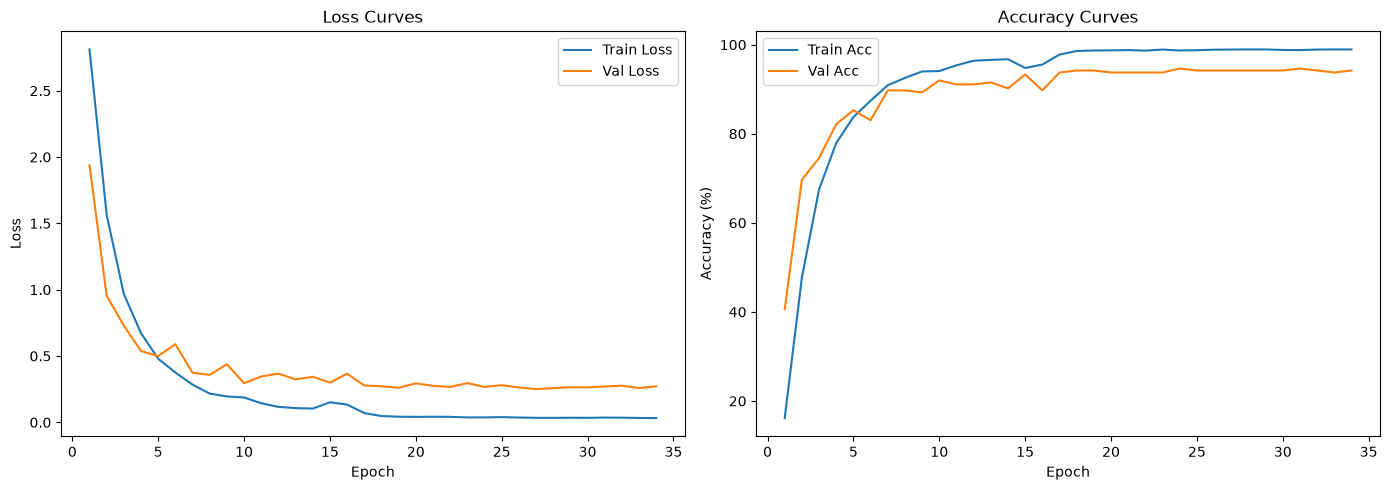

In [7]:
import json
import matplotlib.pyplot as plt
from Training.CNNsaBiLSTM.Config.train_config import RESULTS_DIR

# Load history
history_path = RESULTS_DIR / "train_history.json"
if history_path.exists():
    with open(history_path, "r") as f:
        history = json.load(f)
        
    epochs = range(1, len(history["train_loss"]) + 1)
    
    plt.figure(figsize=(14, 5))
    
    # Loss Curve
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["train_loss"], label="Train Loss")
    plt.plot(epochs, history["val_loss"], label="Val Loss")
    plt.title("Loss Curves")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    
    # Accuracy Curve
    plt.subplot(1, 2, 2)
    plt.plot(epochs, [x*100 for x in history["train_acc"]], label="Train Acc")
    plt.plot(epochs, [x*100 for x in history["val_acc"]], label="Val Acc")
    plt.title("Accuracy Curves")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.legend()
    
    plt.tight_layout()
    plt.show()
else:
    print("History training belum tersedia. Silakan jalankan training terlebih dahulu.")


## 6. Tampilkan Confusion Matrix

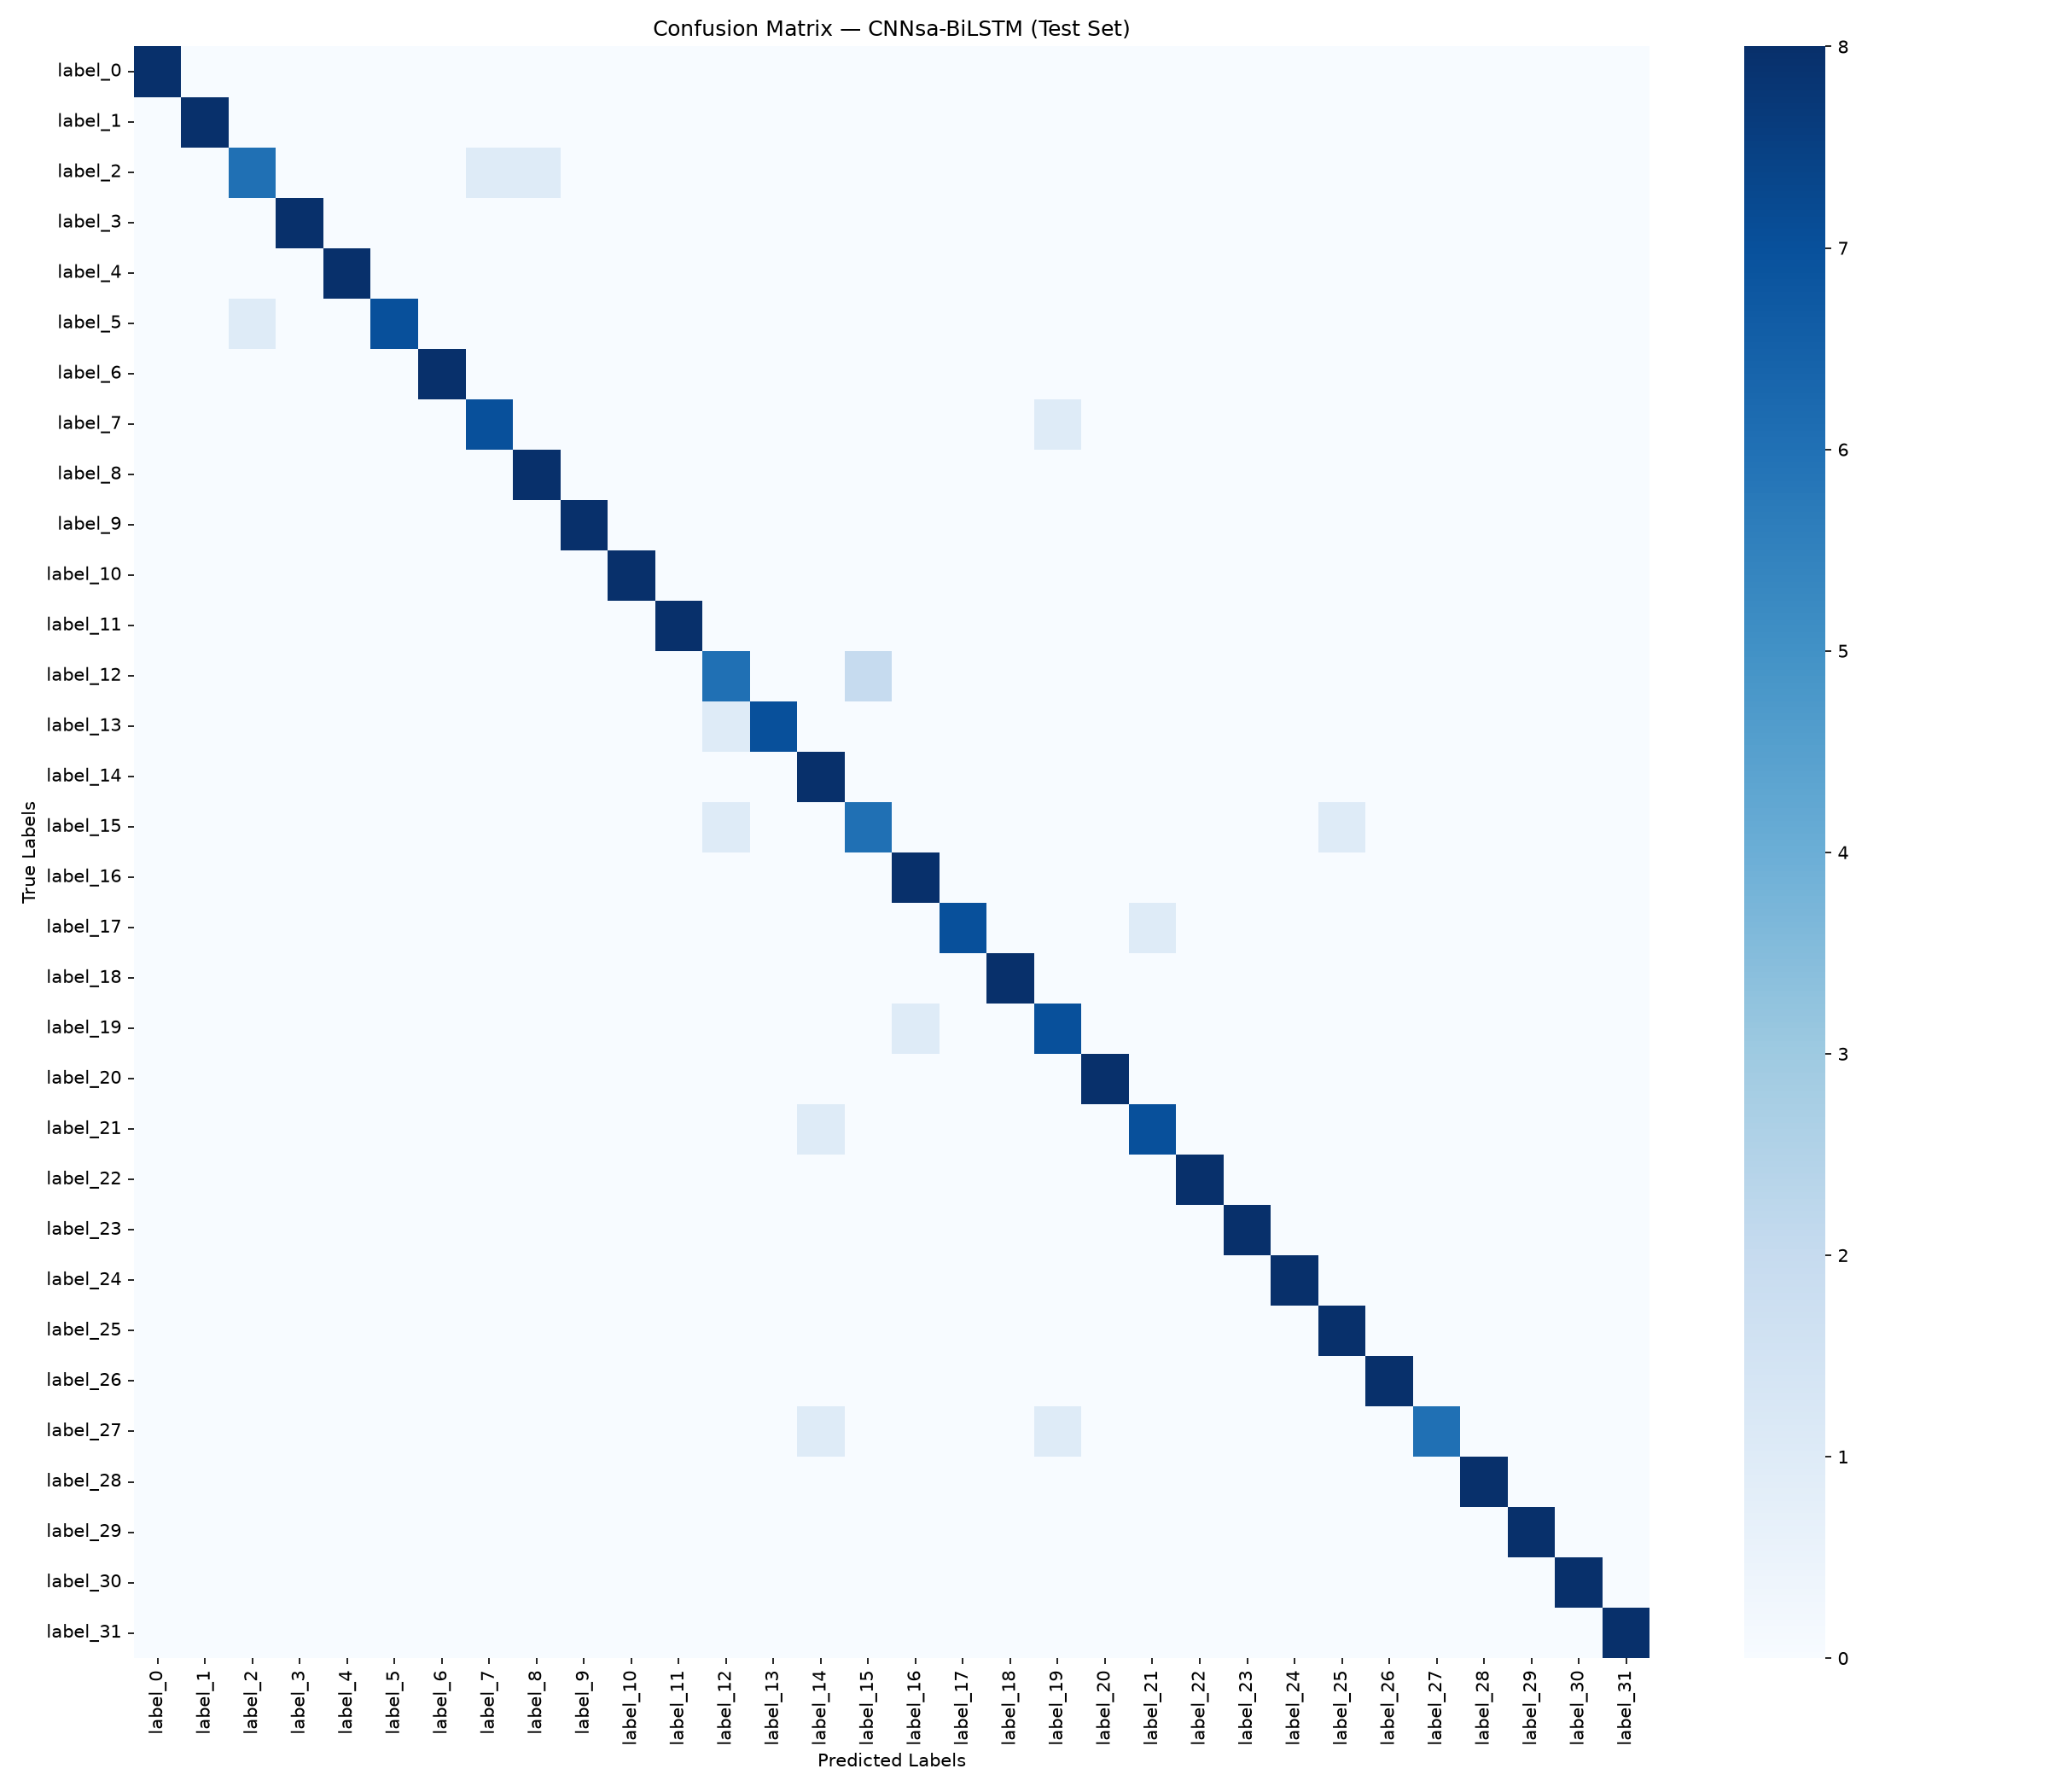

In [8]:
from IPython.display import Image, display
from Training.CNNsaBiLSTM.Config.train_config import RESULTS_DIR

cm_path = RESULTS_DIR / "confusion_matrix_cnnsa_bilstm.png"
if cm_path.exists():
    display(Image(filename=str(cm_path)))
else:
    print("Confusion Matrix image belum dibuat.")
